# MedicStore - Sales Reporting (version 1: notebook)

Solution of the case study described in the Prework 6 guidelines.

Run the cells from top to bottom (**Run All**).


In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from openpyxl.drawing.image import Image

In [2]:
# Paths
# Works from the project root (uv run) and from scripts/ or notebooks/ (Interactive Window)
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA_DIR = ROOT / "data"
INPUT_DIR = DATA_DIR / "input_medicstore"
OUTPUT_DIR = DATA_DIR / "output_medicstore"
OUTPUT_DIR.mkdir(exist_ok=True)

## Objective 1: Automate the consolidation process


In [3]:
# Load the data
# The CSV files use ";" as separator
sales_part1 = pd.read_csv(INPUT_DIR / "Sales_MedicStore_part1.csv", sep=";")
sales_part2 = pd.read_csv(INPUT_DIR / "Sales_MedicStore_part2.csv", sep=";")
mapping = pd.read_excel(INPUT_DIR / "Mapping .xlsx")

In [4]:
# Concatenation: stack part1 and part2 vertically into Sales
sales = pd.concat([sales_part1, sales_part2], ignore_index=True)
print(f"part1: {len(sales_part1)} + part2: {len(sales_part2)} = sales: {len(sales)}")

part1: 19 + part2: 7867 = sales: 7886


In [5]:
# Merge: add the Category column from the mapping table (key = Sub-Category)
df_final = sales.merge(mapping, on="Sub-Category", how="left")

# Sanity checks: no line lost, no unknown sub-category
assert len(df_final) == len(sales), "The merge changed the number of lines"
assert df_final["Category"].notna().all(), (
    "Some sub-categories are not in the mapping table"
)

In [6]:
# Compute total_sales = Quantity x Unit Price
df_final["total_sales"] = df_final["Quantity"] * df_final["Unit Price"]

# Convert the dates (format dd/mm/yyyy) so that Excel reads them as real dates
df_final["Order Date"] = pd.to_datetime(df_final["Order Date"], format="%d/%m/%Y")
df_final["Ship Date"] = pd.to_datetime(df_final["Ship Date"], format="%d/%m/%Y")
df_final.head()

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
0,West Bromwich,United Kingdom,Ellis Ballard,Canon,2017-08-02,ES-2017-5113958,Medicine 1,North,Corporate,2017-08-07,Second Class,England,Imaging Systems,3,142,Equipment,426
1,West Bromwich,United Kingdom,Ellis Ballard,Hoover,2017-08-02,ES-2017-5113958,Medicine 2,North,Corporate,2017-08-07,Second Class,England,Medical Refrigeration Units,7,568,Equipment,3976
2,West Bromwich,United Kingdom,Ellis Ballard,Accos,2017-08-02,ES-2017-5113958,Medicine 3,North,Corporate,2017-08-07,Second Class,England,Surgical Instruments,3,14,Equipment,42
3,Le Bouscat,France,Logan Haushalter,Hon,2017-06-20,ES-2017-2510515,Medicine 4,Central,Consumer,2017-06-20,Same Day,Aquitaine-Limousin-Poitou-Charentes,Over-the-Counter (OTC) Medicines,2,12,Pharmaceuticals,24
4,Le Bouscat,France,Logan Haushalter,Hamilton Beach,2017-06-20,ES-2017-2510515,Medicine 5,Central,Consumer,2017-06-20,Same Day,Aquitaine-Limousin-Poitou-Charentes,Medical Refrigeration Units,5,488,Equipment,2440


In [7]:
# Export the final dataset to Excel
df_final.to_excel(OUTPUT_DIR / "medicstore_final.xlsx", index=False)

## Objective 2: Answer some questions

### Technical questions from the Data Team


In [8]:
# Q1. Number of lines and columns
shapes = {
    "dataset": [
        "Sales_MedicStore_part1.csv",
        "Sales_MedicStore_part2.csv",
        "Mapping.xlsx",
        "final dataset",
    ],
    "nb_lines": [
        sales_part1.shape[0],
        sales_part2.shape[0],
        mapping.shape[0],
        df_final.shape[0],
    ],
    "nb_columns": [
        sales_part1.shape[1],
        sales_part2.shape[1],
        mapping.shape[1],
        df_final.shape[1],
    ],
}
df_shapes = pd.DataFrame(shapes)
df_shapes

,dataset,nb_lines,nb_columns
0,Sales_MedicStore_part1.csv,19,15
1,Sales_MedicStore_part2.csv,7867,15
2,Mapping.xlsx,17,2
3,final dataset,7886,17


In [9]:
# Q2. Column names
list(df_final.columns)

['City',
 'Country',
 'Customer Name',
 'Manufacturer',
 'Order Date',
 'Order ID',
 'Product Name',
 'Region',
 'Segment',
 'Ship Date',
 'Ship Mode',
 'State/Province',
 'Sub-Category',
 'Quantity',
 'Unit Price',
 'Category',
 'total_sales']

In [10]:
# Q3. Top 5 lines
df_final.head(5)

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
0,West Bromwich,United Kingdom,Ellis Ballard,Canon,2017-08-02,ES-2017-5113958,Medicine 1,North,Corporate,2017-08-07,Second Class,England,Imaging Systems,3,142,Equipment,426
1,West Bromwich,United Kingdom,Ellis Ballard,Hoover,2017-08-02,ES-2017-5113958,Medicine 2,North,Corporate,2017-08-07,Second Class,England,Medical Refrigeration Units,7,568,Equipment,3976
2,West Bromwich,United Kingdom,Ellis Ballard,Accos,2017-08-02,ES-2017-5113958,Medicine 3,North,Corporate,2017-08-07,Second Class,England,Surgical Instruments,3,14,Equipment,42
3,Le Bouscat,France,Logan Haushalter,Hon,2017-06-20,ES-2017-2510515,Medicine 4,Central,Consumer,2017-06-20,Same Day,Aquitaine-Limousin-Poitou-Charentes,Over-the-Counter (OTC) Medicines,2,12,Pharmaceuticals,24
4,Le Bouscat,France,Logan Haushalter,Hamilton Beach,2017-06-20,ES-2017-2510515,Medicine 5,Central,Consumer,2017-06-20,Same Day,Aquitaine-Limousin-Poitou-Charentes,Medical Refrigeration Units,5,488,Equipment,2440


In [11]:
# Q4. Last 5 lines
df_final.tail(5)

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
7881,Bagnolet,France,Katherine Ducich,Acco,2019-08-22,IT-2019-3090371,Medicine 45,Central,Consumer,2019-08-26,Standard Class,Ile-de-France,Wound Care Products,3,51,Supplies,153
7882,Bagnolet,France,Katherine Ducich,Rubbermaid,2019-08-22,IT-2019-3090371,Medicine 661,Central,Consumer,2019-08-26,Standard Class,Ile-de-France,Waiting Room Furnishings,8,110,Furniture,880
7883,Nuremberg,Germany,Laura Armstrong,Cardinal,2019-04-30,ES-2019-4251554,Medicine 205,Central,Corporate,2019-05-05,Standard Class,Bavaria,Wound Care Products,8,49,Supplies,392
7884,Nuremberg,Germany,Laura Armstrong,Acme,2019-04-30,ES-2019-4251554,Medicine 1096,Central,Corporate,2019-05-05,Standard Class,Bavaria,Personal Protective Equipment (PPE),2,39,Supplies,78
7885,Nuremberg,Germany,Laura Armstrong,Stanley,2019-04-30,ES-2019-4251554,Medicine 814,Central,Corporate,2019-05-05,Standard Class,Bavaria,Medical Consumables,12,47,Supplies,564


In [12]:
# Q5. General statistical description (numeric, date and text columns)
df_describe = df_final.describe(include="all")
df_describe

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
count,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886.000000,7886.000000,7886,7886.000000
unique,965,15,792,72,NaN,3744,1803,3,3,NaN,4,124,17,NaN,NaN,4,NaN
top,London,France,John Murray,Smead,NaN,ES-2017-5776825,Medicine 210,Central,Consumer,NaN,Standard Class,England,Medical Consumables,NaN,NaN,Supplies,NaN
freq,205,2190,28,292,NaN,12,23,4593,4098,NaN,4804,1187,1156,NaN,NaN,2888,NaN
mean,NaN,NaN,NaN,NaN,2018-03-03 05:35:37.357342,NaN,NaN,NaN,NaN,2018-03-07 05:40:22.216586,NaN,NaN,NaN,3.791022,77.372432,NaN,290.492392
min,NaN,NaN,NaN,NaN,2016-01-01 00:00:00,NaN,NaN,NaN,NaN,2016-01-05 00:00:00,NaN,NaN,NaN,1.000000,2.000000,NaN,3.000000
25%,NaN,NaN,NaN,NaN,2017-03-21 00:00:00,NaN,NaN,NaN,NaN,2017-03-25 00:00:00,NaN,NaN,NaN,2.000000,16.000000,NaN,49.000000
50%,NaN,NaN,NaN,NaN,2018-01-19 00:00:00,NaN,NaN,NaN,NaN,2018-01-25 00:00:00,NaN,NaN,NaN,3.000000,37.000000,NaN,117.000000
75%,NaN,NaN,NaN,NaN,2019-03-27 18:00:00,NaN,NaN,NaN,NaN,2019-03-31 00:00:00,NaN,NaN,NaN,5.000000,90.000000,NaN,312.000000
max,NaN,NaN,NaN,NaN,2019-12-31 00:00:00,NaN,NaN,NaN,NaN,2020-01-05 00:00:00,NaN,NaN,NaN,14.000000,908.000000,NaN,7952.000000


### Business questions from the Operational Team


In [13]:
# Q1. Number of orders
# One order can contain several lines (one per product), so we count the unique Order IDs
total_orders = df_final["Order ID"].nunique()
print(f"{total_orders} orders ({len(df_final)} order lines)")

3744 orders (7886 order lines)


In [14]:
# Q2. Total sales amount
total_sales_amount = df_final["total_sales"].sum()
print(f"Total sales amount: {total_sales_amount:,}")

Total sales amount: 2,290,823


In [15]:
# Q3. Top 3 customers by number of orders
orders_per_customer = (
    df_final.groupby("Customer Name")["Order ID"].nunique().sort_values(ascending=False)
)
top3_customers = orders_per_customer.head(3)
top3_customers

Customer Name
Frank Olsen       13
Paul Stevenson    12
Yoseph Carroll    12
Name: Order ID, dtype: int64

In [16]:
# Q4. Total sales for France
is_france = df_final["Country"] == "France"
total_sales_france = df_final.loc[is_france, "total_sales"].sum()
print(f"Total sales for France: {total_sales_france:,}")

Total sales for France: 650,730


In [17]:
# Q5. Share of France in the total global sales
ratio_sales_france = total_sales_france / total_sales_amount
print(f"France represents {ratio_sales_france:.1%} of the total sales")

France represents 28.4% of the total sales


## Objective 3 (optional): Graph analysis

The guidelines ask for "visits per gender / department", which do not exist in this
dataset. We adapt them to the sales data: orders per country and sales per category.


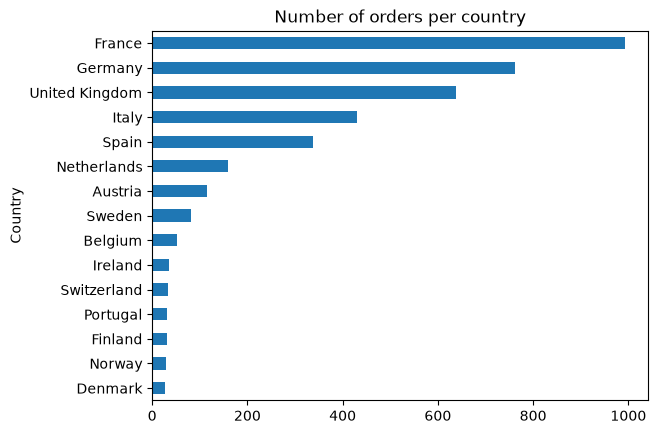

In [18]:
# Number of orders per country
fig, ax = plt.subplots()
df_final.groupby("Country")["Order ID"].nunique().sort_values().plot.barh(
    ax=ax, title="Number of orders per country"
)
fig.savefig(OUTPUT_DIR / "orders_per_country.png", bbox_inches="tight")

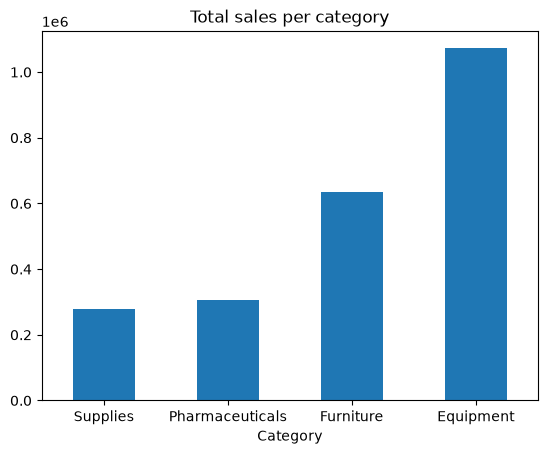

In [19]:
# Total sales per category
fig, ax = plt.subplots()
df_final.groupby("Category")["total_sales"].sum().sort_values().plot.bar(
    ax=ax, title="Total sales per category", rot=0
)
fig.savefig(OUTPUT_DIR / "sales_per_category.png", bbox_inches="tight")

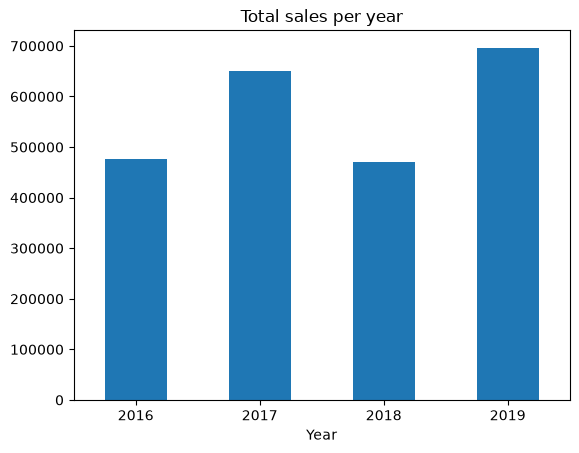

In [20]:
# Total sales per year
fig, ax = plt.subplots()
df_final.groupby(df_final["Order Date"].dt.year)["total_sales"].sum().plot.bar(
    ax=ax, title="Total sales per year", rot=0
)
ax.set_xlabel("Year")
fig.savefig(OUTPUT_DIR / "sales_per_year.png", bbox_inches="tight")

## Objective 4: Export the analysis


In [21]:
# Store the answers in a dictionary, then a DataFrame
# The top 3 customers are written as one text: "name (n orders), ..."
top3_text = ", ".join(f"{name} ({n} orders)" for name, n in top3_customers.items())

dict_analysis = {
    "How many lines are in Sales_MedicStore_part1.csv": len(sales_part1),
    "How many lines are in Sales_MedicStore_part2.csv": len(sales_part2),
    "How many lines are in Mapping.xlsx": len(mapping),
    "How many orders do we have": total_orders,
    "What is the total sales amount": total_sales_amount,
    "Who are the top 3 customers (order count)": top3_text,
    "What is the total Sales for France": total_sales_france,
    "How much does the total Sales for France represent compare to the total global Sales": ratio_sales_france,
}
df_analysis = pd.DataFrame(list(dict_analysis.items()), columns=["Question", "Answer"])
df_analysis

,Question,Answer
0,How many lines are in Sales_MedicStore_part1.csv,19
1,How many lines are in Sales_MedicStore_part2.csv,7867
2,How many lines are in Mapping.xlsx,17
3,How many orders do we have,3744
4,What is the total sales amount,2290823
5,Who are the top 3 customers (order count),"Frank Olsen (13 orders), Paul Stevenson (12 or..."
6,What is the total Sales for France,650730
7,How much does the total Sales for France repre...,0.284059


In [22]:
# Export the tables and the graphs into one Excel file, one sheet each
graphs = ["orders_per_country", "sales_per_category", "sales_per_year"]

with pd.ExcelWriter(OUTPUT_DIR / "medicstore_analysis.xlsx") as writer:
    df_final.to_excel(writer, sheet_name="final_dataset", index=False)
    df_shapes.to_excel(writer, sheet_name="technical_q1_shapes", index=False)
    df_describe.to_excel(writer, sheet_name="technical_q5_describe")
    df_analysis.to_excel(writer, sheet_name="business_questions", index=False)

    sheet = writer.book.create_sheet("graphs")
    for i, name in enumerate(graphs):
        sheet.add_image(Image(OUTPUT_DIR / f"{name}.png"), f"A{1 + 25 * i}")

print(f"Analysis exported to {OUTPUT_DIR}")

Analysis exported to /Users/jade/code/emlyon/python_programming_class/wu_course06/data/output_medicstore
